## Programa para Adquirir Dados do plano da amostra

In [1]:
import time
import numpy as np
import time 
from structured_optics import *
from structured_optics.hologram import slm_hologram
from structured_optics.slmdisplay import My_SLM
from camera import *
from utils import *
import h5py
from pathlib import Path

## Funções

In [2]:
def calculate_fix_std_LG(p, l):
    N = 2*p + abs(l) + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({p},{l}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu                  # waist on the SLM

def calculate_fix_std_HG(n):
    N = 2*n + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({n},{0}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu 

    

## Parâmetros

In [3]:
FOLDER = 'Amostras_10_2026_sample_plane/'


#parametros laser e slm
pixel_size = 8e-6  #tamanho do pixel do slm 
lamb = 633e-9   #comprimento de onda
waist = 0.3e-3  #cintura do feixe que sai do slm
x_grating = 3
y_grating = 4

#parametros lentes e propagação
mu = 0.6930012799317185/0.5 #parâmetro de magnificação devido ao sistema 4F após o SLM
z = 0 #Distância entre o waist pós 4F e a amostra, utilizado para calcular fix std
C = 0.65e-3#0.5e-3  #std a ser fixado
ANGLE = -4.5*np.pi/180


#parametros motor de passo
resolution = 50  #Resolução dos motores de passo
step_size = 200e-9 #tamanho do passo dos motores de passo
NUM_REP = 5  #numero de repetições da medida
z_start = 0.004

#parametros camera
EXPO = 1/9091   #exposição camera em segundos
BIT = 8     #bitdepth da camera
pixel_cam = 3.75e-6 #tamanho do pixel da camera
width_cam = 1280 #largura da camera
height_cam = 960 #altura da camera
NUM_BACK = 5 #numero de imagens para calcular o background




In [ ]:
"""folder = Path(FOLDER)
folder.mkdir(exist_ok=True)"""  #Cria a pasta pra salvar os arquivos, só precisa ser rodado uma vez, por isso ta comentado.

## Primeiro alinhamento e check de equipamentos

In [4]:
#inicializa camera, slm e lista de modos a serem medidos (até ordem 5)

slm = My_SLM(1)
width = slm.width
height = slm.height

cam = init_camera(bitdepth=BIT, exposure_s = EXPO)


hg_modes = [[0,0], [0,1], [1,0], [2,0], [1,1], [0,2], [3,0], 
            [2,1], [1,2], [0,3], [4,0], [3,1], [2,2], [1,3], 
            [0,4], [5,0], [4,1], [3,2], [2,3], [1,4], [0,5]]
lg_modes = [[0,0], [0,1], [0,-1], [0,2], [1,0], [0,-2], [0,3], 
            [1,1], [1,-1], [0,-3], [0,4], [1, 2], [1,-2], [2, 0], 
            [0,-4], [0,5], [1,3], [1, -3], [2, 1], [2,-1], [0,-5]]

In [5]:
#inicializa objeto beam que contém os parâmetros do feixe gerado

width = slm.width
height = slm.height

beam = Beam(nix = pixel_size*width/2, Dx = width,
            niy = pixel_size*height/2, Dy = height,
            waist = waist, lamb = lamb)

k = beam.k()

In [6]:
#Define qual o campo do objeto beam, gera um holograma a partir desse campo e atualiza a máscara do slm com esse holograma

beam.lg(2,2, angle=ANGLE)
#beam.triangle()
holo = slm_hologram(beam, x_grating, y_grating)
slm.update_image(holo)

## Dados LG waist normal

In [7]:
beam.waist = waist

with h5py.File(f"{FOLDER}data_LG.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'magnification': mu,
        'waist': waist,
        'z': z,
        'lamb': lamb,
    })

    images_ds = file.create_dataset("images", (len(lg_modes), height_cam, width_cam), dtype='uint8')
    index_ds = file.create_dataset("index", (len(lg_modes), 2), dtype='int')

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(0.1)
        

    for i, mode in enumerate(lg_modes):
        l = mode[1]
        p = mode[0]
        index_ds[i] = mode

        beam.lg(l,p, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(0.2)
        img = take_picture(cam)
        if np.max(img) >254:
            print(f"mode lg{mode} saturated")
        images_ds[i] = img


## Dados HG waist normal

In [8]:
beam.waist = waist

with h5py.File(f"{FOLDER}data_HG.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'magnification': mu,
        'waist': waist,
        'z': z,
        'lamb': lamb,
    })

    images_ds = file.create_dataset("images", (6, height_cam, width_cam), dtype='uint8')
    index_ds = file.create_dataset("index", (6, 2), dtype='int')

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(0.1)
        

    for n in range(6):
        index_ds[n] = [n,0]

        beam.hg(n,0, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(0.2)

        img = take_picture(cam)
        if np.max(img) >254:
            print(f"mode hg{mode} saturated")
        images_ds[n] = img

## Dados LG std fixo

In [9]:
with h5py.File(f"{FOLDER}data_LG_fix.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'magnification': mu,
        'C': C,
        'z': z,
        'lamb': lamb,
    })

    images_ds = file.create_dataset("images", (len(lg_modes), height_cam, width_cam), dtype='uint8')
    index_ds = file.create_dataset("index", (len(lg_modes), 2), dtype='int')

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(0.1)
        


    for i, mode in enumerate(lg_modes):
        l = mode[1]
        p = mode[0]
        index_ds[i] = mode

        beam.waist = calculate_fix_std_LG(p,l)
        beam.lg(l,p, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(0.2)

        img = take_picture(cam)
        if np.max(img) >254:
            print(f"mode lg{mode} saturated")
        images_ds[i] = img


## Dados HG std fixo

In [10]:
with h5py.File(f"{FOLDER}data_HG_fix.h5", "w") as file:
    file.attrs.update({
        'expo': f"{EXPO}s",
        'bit_depth': BIT,
        'step_size_nm': int(round(step_size * 1e9)),
        'cam_pixel_size_um': pixel_cam * 1e6,
        'magnification': mu,
        'C': C,
        'z': z,
        'lamb': lamb,
    })

    images_ds = file.create_dataset("images", (6, height_cam, width_cam), dtype='uint8')
    index_ds = file.create_dataset("index", (6, 2), dtype='int')

    slm.update_image(np.zeros((height, width), dtype='uint8'))
    time.sleep(0.2)
    background = file.create_dataset("background", (NUM_BACK, height_cam, width_cam), dtype='uint8')
    for i in range(NUM_BACK):
        background[i] = take_picture(cam)
        time.sleep(0.1)
        


    for n in range(6):
        index_ds[n] = [n,0]

        beam.waist = calculate_fix_std_HG(n)
        beam.hg(n,0, angle=ANGLE)
        holo = slm_hologram(beam, x_grating, y_grating)
        slm.update_image(holo)
        time.sleep(0.2)

        img = take_picture(cam)
        if np.max(img) >254:
            print(f"mode hg{mode} saturated")
        images_ds[n] = img

Atributos:
  bit_depth: 8
  cam_pixel_size_um: 3.75
  expo: 0.00010999890001099989s
  lamb: 6.33e-07
  magnification: 1.386002559863437
  step_size_nm: 200
  waist: 0.0003
  z: 0

Datasets:
  background: shape=(5, 960, 1280), dtype=uint8
  images: shape=(21, 960, 1280), dtype=uint8
  index: shape=(21, 2), dtype=int64


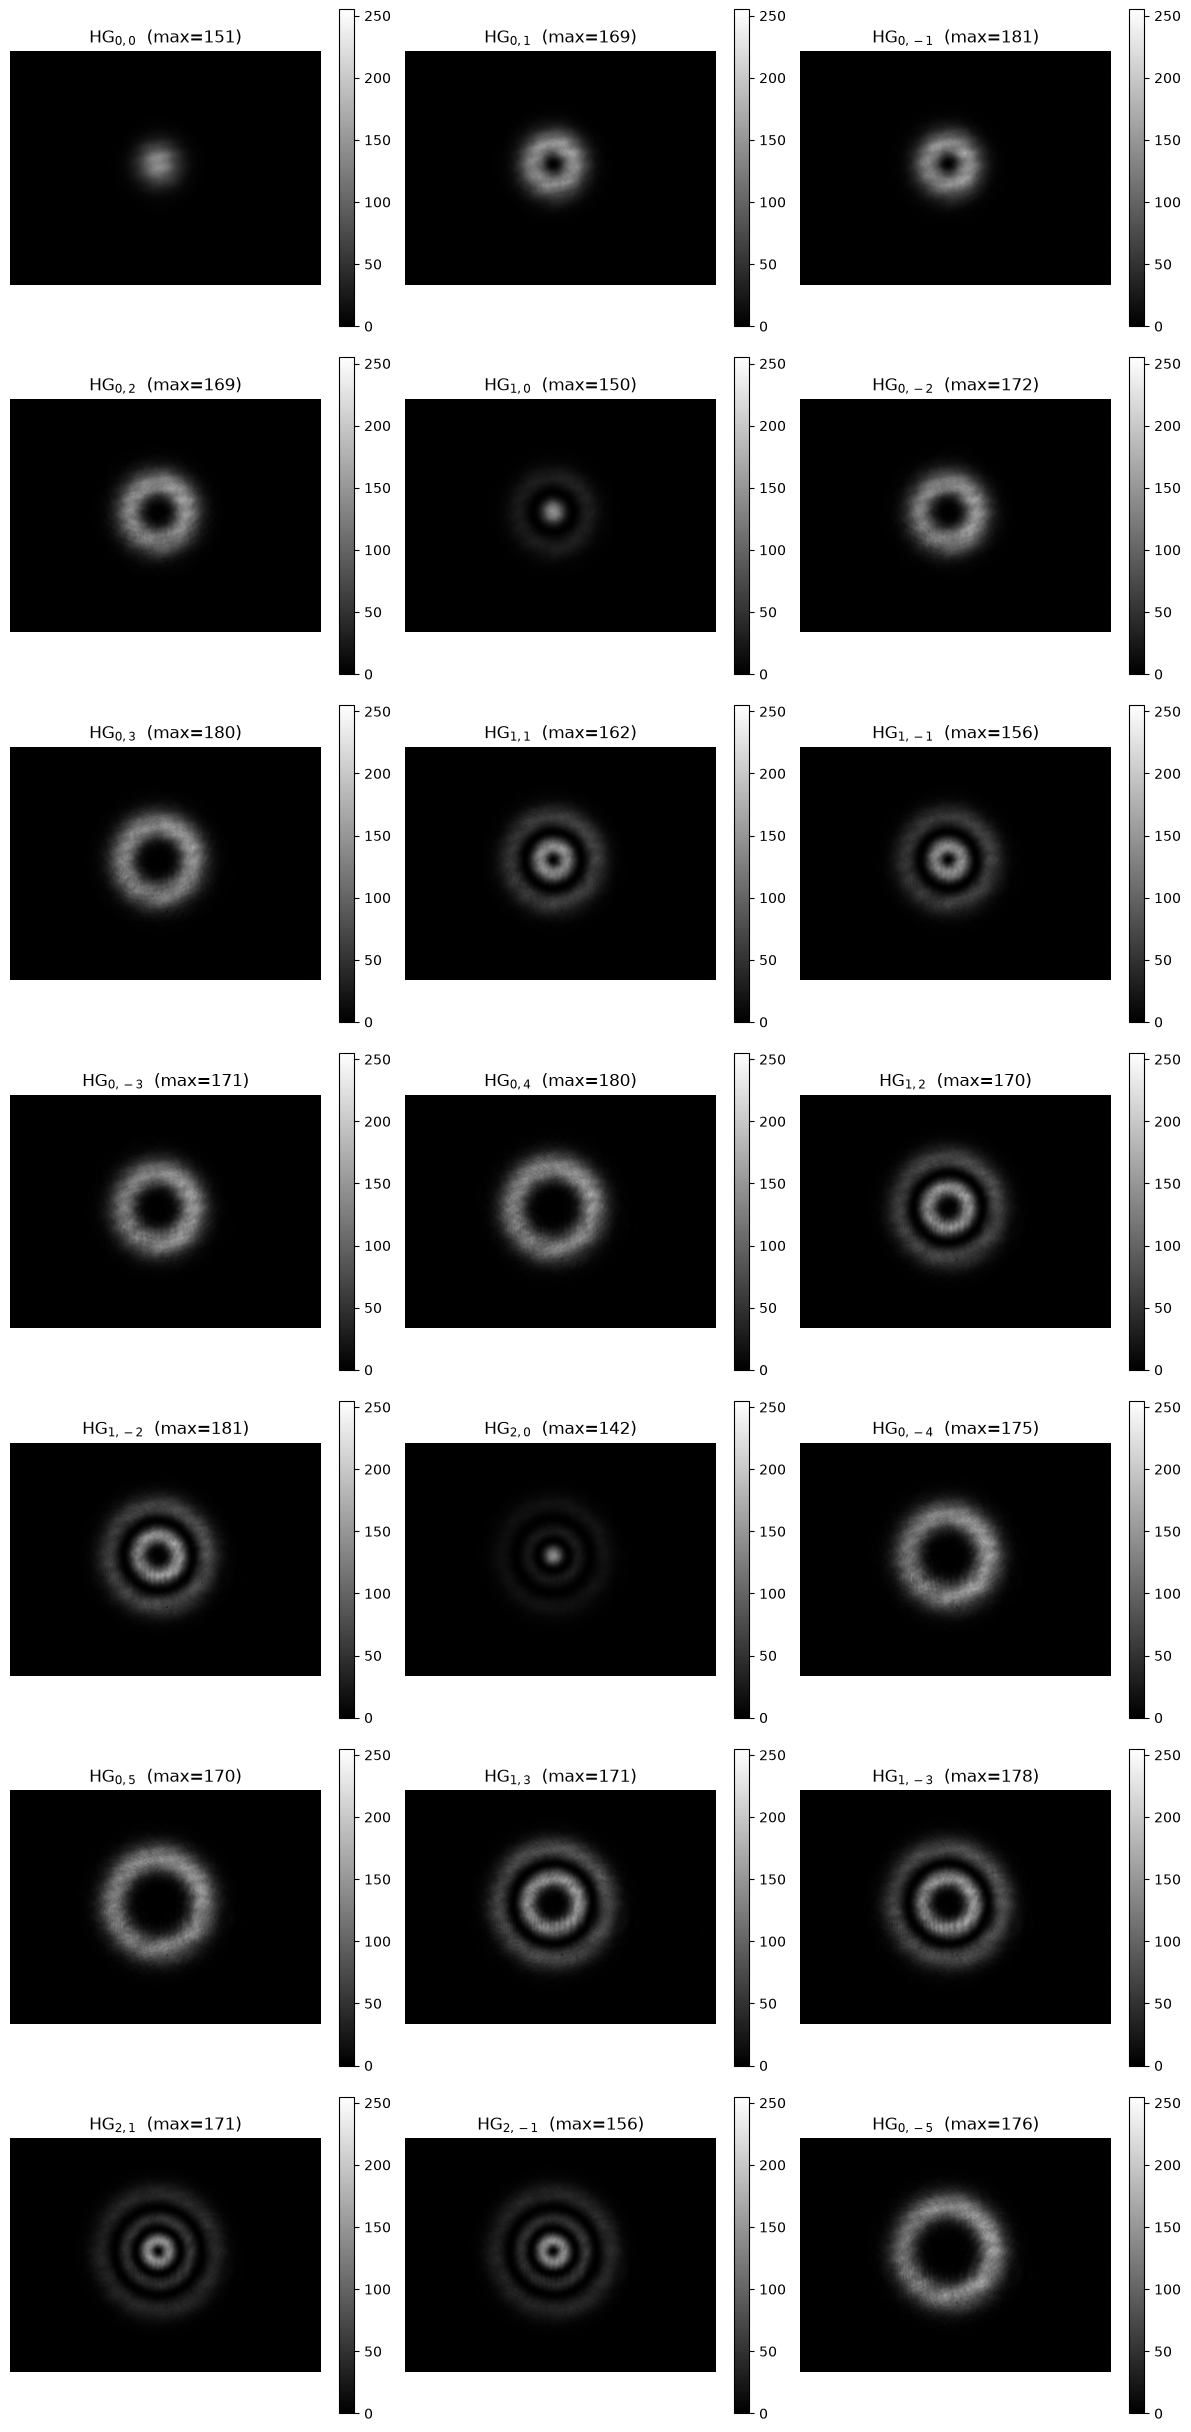

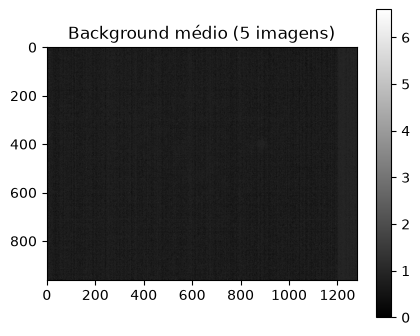

In [11]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

FOLDER = "Amostras_10_2026_sample_plane/"  # ajuste para sua pasta

with h5py.File(f"{FOLDER}data_LG.h5", "r") as file:
    # Atributos
    print("Atributos:")
    for key, value in file.attrs.items():
        print(f"  {key}: {value}")

    print("\nDatasets:")
    for name, ds in file.items():
        print(f"  {name}: shape={ds.shape}, dtype={ds.dtype}")

    images = file["images"][:]
    index = file["index"][:]
    background = file["background"][:]

# Imagens adquiridas
n_img = len(images)
ncols = 3
nrows = int(np.ceil(n_img / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows),
                         squeeze=False)
for ax, img, (n, m) in zip(axes.ravel(), images, index):
    im = ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"HG$_{{{n},{m}}}$  (max={img.max()})")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046)

for ax in axes.ravel()[n_img:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Background médio (opcional)
plt.figure(figsize=(5, 4))
plt.imshow(background.mean(axis=0), cmap="gray")
plt.title(f"Background médio ({len(background)} imagens)")
plt.colorbar()
plt.show()

In [12]:
close_camera(cam)
slm.close()